# 선형회귀- 다중회귀(길이, 높이, 두께 : 특성이 여러개 일때)

1. linearRegression
2. 다중회귀(Multiple Regression)
- 이제부터는 그래프 못그림
- 특성값을 더 추가 : PolynomialFeatures을 추가한 이유는 정확도를 더 높이기 위해
3. degree를 추가
- 과대적합 : 훈련데이터 정확도가 높은데 테스트 데이터는 현저히 정확도가 떨어짐(-나옴)
4. 규제
- 정규화작업을 해야 규제가 가능
- Ridge 규제
- 옵션 : alpha 강도조절 과대적합의 문제를 해결

In [385]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [386]:
df=pd.read_csv('data/perch_full.csv', sep=',')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [387]:
# 무게 데이터 (label)
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [388]:
# 학습/ 테스트 데이터 분리
train_data, test_data, train_label, test_label = train_test_split(df, perch_weight,random_state=42)

In [389]:
# 특성값을 추가
# length, height, width
# lenght**2, height**2, width**2


# degree 
# include_bias=False : 1은 제외
# degree 가 늘어날수록 과대적합이 될수 있음, 적당한 값을 찾기
poly = PolynomialFeatures(degree=16, include_bias=False)


In [390]:
# 다항특성 추가 (행 개수보다 많은건 좋지 않음.)
poly.fit(train_data)
train_poly= poly.transform(train_data)
test_poly = poly.transform(test_data)
print(train_poly.shape)

(42, 968)


In [396]:
# 규제, 정규화 작업 진행 - 테스트 데이터 정확도를 높일수 있음 ( 현재 -임)
# StandardScaler()

ss=StandardScaler()
ss.fit(train_poly)
train_scaled=ss.transform(train_poly)
test_scaled =ss.transform(test_poly)

In [404]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score=[]
test_score=[]

for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled, train_label)

    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)

    train_score.append(score)
    test_score.append(score2)
print('완료')


완료


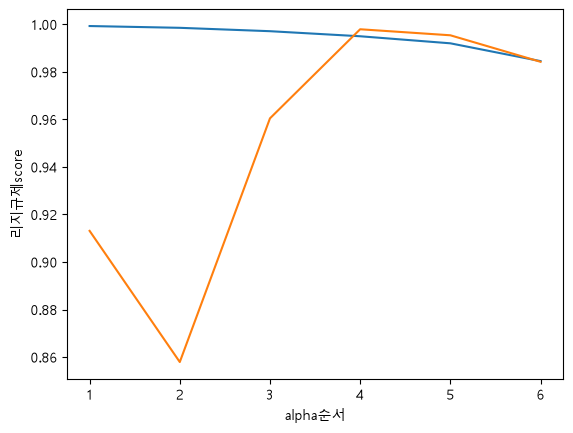

In [405]:
# 선그래프
no_list=[1,2,3,4,5,6]
plt.plot(no_list, train_score)
plt.plot(no_list, test_score)
plt.xlabel('alpha순서')
plt.ylabel('리지규제score')

plt.show()

In [407]:
ridge = Ridge(alpha=100)
ridge.fit(train_scaled, train_label)

# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2) # test가 더 높으면 과도적합

train정확도 :  0.9845264472982629
test정확도 :  0.9842357688653649


In [393]:
#  다항식을 만든 형태를 알려줌
# print(poly.get_feature_names_out())

In [394]:
# 데이터 학습
lr=LinearRegression()
lr.fit(train_data, train_label)

# 예측
predict = lr.predict(test_data)
print("예측:",predict)

# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2) # test가 더 높으면 과도적합

예측: [-322.78309496   52.96101903  329.77783424  171.46884473  149.65836217
  789.639144    383.68482432  250.05247716  813.2470793   126.13660027
  980.20626415  -33.35965799  357.76466578  421.8675313 ]
train정확도 :  0.9559326821885706
test정확도 :  0.8796419177546366


In [395]:
# degreen -2 / 특성을 55개로 변경해서 예측

# 데이터 학습
lr=LinearRegression()
lr.fit(train_poly, train_label)

# 예측
predict = lr.predict(test_poly)
print("예측:",predict)

# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print("train정확도 : ",score)
print("test정확도 : ",score2)

예측: [ 159.30133767  159.35046576  159.42917868  159.73102976  159.14087667
  713.69345406  131.49561783  160.52842927  888.28797296  159.46917553
 -214.72740381  159.3067839   161.12729491  178.67022062]
train정확도 :  0.9453093526621708
test정확도 :  -0.1355617036882999
